In [1]:
import numpy as np
import matplotlib.pyplot as plt 

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
all_data = np.loadtxt("../../data/all_descriptor_data.txt")

In [6]:
indices = [1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 16, 17]

In [18]:
centered = (all_data[:, indices] - np.mean(all_data[:, indices], axis = 0) ) / np.std(all_data[:, indices], axis = 0)

In [19]:
cov = (centered.T @ centered)

In [20]:
eigenvalues, eigenvectors = np.linalg.eig(cov)

In [22]:
sorted_indices = np.argsort(eigenvalues)[::-1]
values_sorted = eigenvalues[sorted_indices]
vectors_sorted = eigenvectors[:,sorted_indices]

In [ ]:
header = ["area", "ellipse aspect ratio", "perimeter", "solidity", "hydraulic diameter", "max chord length", "r_max", "r_min", "r_average", "gravelius compactness", "dev from insc. disk", "dev from circ. disk", "isoperimetric quotient", "morton spreading index"]

In [44]:
explained_variances = values_sorted / np.sum(eigenvalues)

cumul_explained_variances = np.cumsum(values_sorted) / np.sum(eigenvalues)

In [55]:
loadings = vectors_sorted.T * np.sqrt(explained_variances)

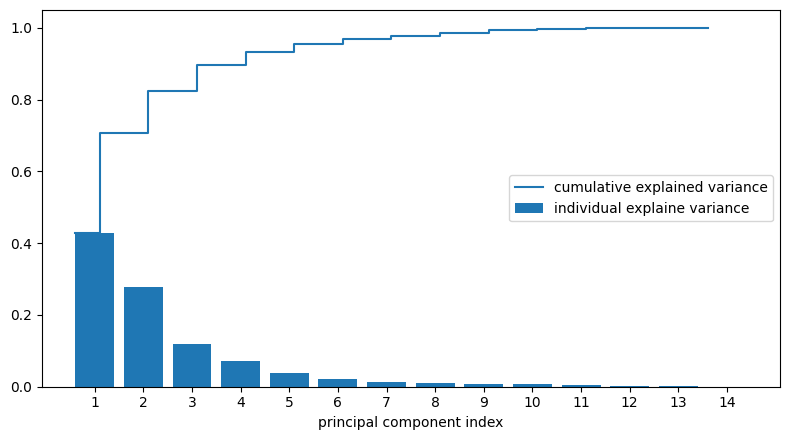

In [95]:
fig, ax = plt.subplots(figsize = (8, 4.5))

ax.bar(np.arange(1,15), height = explained_variances, width = 0.8, label ="individual explaine variance")
ax.step(np.arange(0.6,14.6), cumul_explained_variances , label = "cumulative explained variance", where ="mid")
ax.set_xticks(np.arange(1,15))
ax.legend(loc = "right")
ax.set_xlabel("principal component index")
plt.tight_layout()
plt.savefig("../../temp/Cumulative_Explained_Variance.png", dpi = 200)

plt.show()

In [73]:
from matplotlib.cm import tab20b

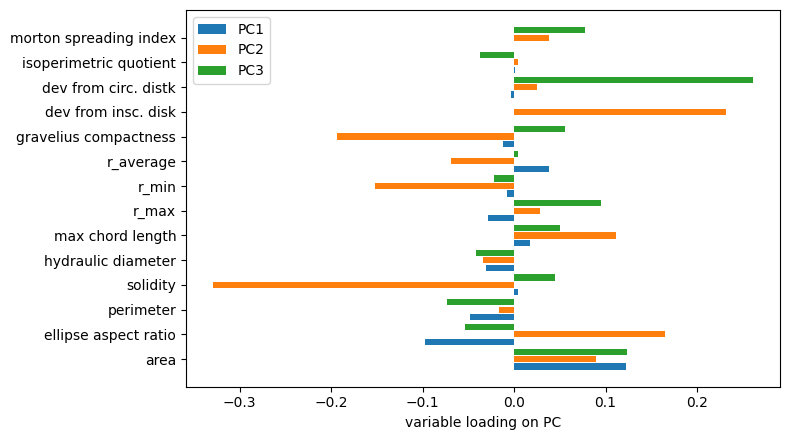

In [101]:
fig, ax = plt.subplots(figsize = (8, 4.5))

ax.barh(np.arange(-0.3,13.7, 1),width=loadings[:, 0]*np.sqrt(explained_variances), height=0.25, label = "PC1")
ax.barh(np.arange(0,14, 1),width=loadings[:, 1], height=0.25, label = "PC2")
ax.barh(np.arange(0.3,14.3, 1),width=loadings[:, 2], height=0.25, label = "PC3")

ax.set_yticks(np.arange(0, 14))
ax.set_yticklabels(header)
ax.legend()
ax.set_xlabel("variable loading on PC")

plt.tight_layout()
plt.savefig("../../temp/PCA_Loadings.png", dpi = 200)
plt.show()

In [61]:
pca_components = vectors_sorted[:, :3]
projected_data = np.dot(centered, pca_components)

In [67]:
correlation_coefficients = np.corrcoef(centered, rowvar=False)


In [86]:
import colorcet

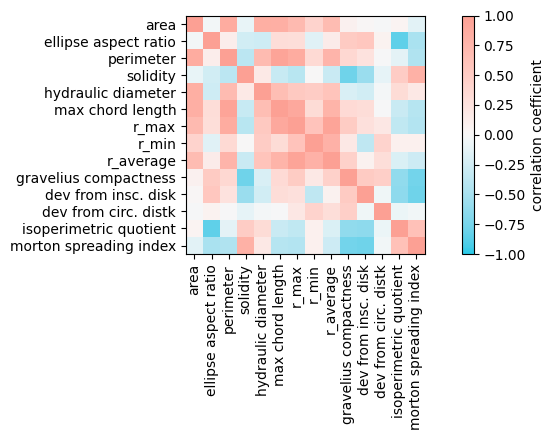

In [99]:
fig, ax = plt.subplots(figsize = (8, 4.5))

im = ax.imshow(correlation_coefficients, cmap = colorcet.cm.diverging_tritanopic_cwr_75_98_c20, vmax=1, vmin=-1)
ax.set_yticks(np.arange(0, 14))
ax.set_yticklabels(header)

ax.set_xticks(np.arange(0, 14))
ax.set_xticklabels(header, rotation=90)

cb = plt.colorbar(im)
cb.set_label("correlation coefficient")

plt.tight_layout()
plt.savefig("../../temp/PCA_CorrelationCoefficients.png", dpi = 200)

plt.show()

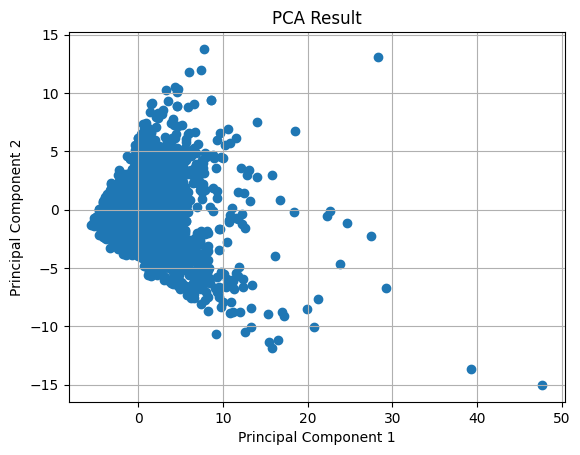

In [62]:
plt.scatter(projected_data[:, 0], projected_data[:, 1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Result')
plt.grid(True)
plt.show()

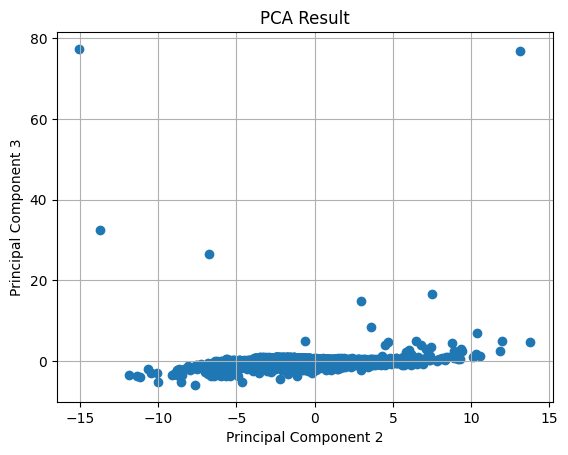

In [63]:
plt.scatter(projected_data[:, 1], projected_data[:, 2])
plt.xlabel('Principal Component 2')
plt.ylabel('Principal Component 3')
plt.title('PCA Result')
plt.grid(True)
plt.show()